## Experiment 8 — Classification Models & ROC Analysis
**Dataset:** Iris Dataset (Fisher's Classic)  
**Objective:** Build and compare three binary classifiers, tune KNN hyperparameters via cross-validation, and evaluate discriminative power using ROC-AUC.  
**Techniques:** Logistic Regression (with odds ratios), K-Nearest Neighbours (K-tuning), Gaussian Naive Bayes, StandardScaler pipeline, confusion matrix, classification report, ROC curves, AUC comparison.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             roc_curve, roc_auc_score)

### 1. Setup & Imports
Import scikit-learn classifiers (LogisticRegression, KNeighborsClassifier, GaussianNB), preprocessing (StandardScaler), evaluation utilities (ROC curve, AUC, classification_report), and visualisation libraries.

In [2]:
df = pd.read_csv("Iris.csv")
print("Dataset shape:", df.shape)

Dataset shape: (150, 6)


### 2. Load & Prepare Dataset
Load the preprocessed dataset, define the binary target variable, and select numeric predictor features. Inspect class distribution to check for imbalance that might require stratified splitting.

In [3]:
target = "Species"
positive_class = "Iris-virginica"
predictors = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]
model_df = df[[target] + predictors].dropna()

X = model_df[predictors]
y = (model_df[target] == positive_class).astype(int)
print("Target distribution (1=Iris-virginica, 0=Others):\n", y.value_counts(normalize=True).round(3))

Target distribution (1=Iris-virginica, 0=Others):
 Species
0    0.667
1    0.333
Name: proportion, dtype: float64


### 3. Train / Test Split
Split data 80/20 with stratification to preserve class proportions in both sets. Stratified splitting is especially important for imbalanced classification tasks.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Train set size:", len(X_train), "| Test set size:", len(X_test))

Train set size: 120 | Test set size: 30


### 4. Feature Scaling
Apply StandardScaler fitted on the training set and transform both train and test sets. Scaling is essential for Logistic Regression and KNN, which are sensitive to feature magnitudes.

In [5]:
results, preds, probs = [], {}, {}

def evaluate(name, classifier):
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", classifier)
    ])
    model.fit(X_train, y_train)
    preds[name] = model.predict(X_test)
    probs[name] = model.predict_proba(X_test)[:, 1]
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, preds[name]),
        "Precision": precision_score(y_test, preds[name], zero_division=0),
        "Recall": recall_score(y_test, preds[name], zero_division=0),
        "F1": f1_score(y_test, preds[name], zero_division=0),
        "AUC": roc_auc_score(y_test, probs[name])
    })
    print(name, results[-1])
    return model

### 5. Logistic Regression
Train a Logistic Regression model and interpret coefficients as log-odds. Exponentiate coefficients to obtain odds ratios, which communicate the multiplicative change in odds for a one-unit increase in each predictor.

In [6]:
logistic = evaluate("Logistic Regression", LogisticRegression(max_iter=1000, random_state=42))
coef = logistic.named_steps["classifier"].coef_[0]
coef_table = pd.DataFrame({"Coefficient": coef, "Odds Ratio": np.exp(coef)}, index=predictors)
print(coef_table.round(4))

knn = evaluate("KNN (K=5)", KNeighborsClassifier(n_neighbors=5))
nb = evaluate("Gaussian Naive Bayes", GaussianNB())

Logistic Regression {'Model': 'Logistic Regression', 'Accuracy': 1.0, 'Precision': 1.0, 'Recall': 1.0, 'F1': 1.0, 'AUC': 1.0}
               Coefficient  Odds Ratio
SepalLengthCm       0.2787      1.3215
SepalWidthCm       -0.4574      0.6329
PetalLengthCm       2.1222      8.3493
PetalWidthCm        2.8668     17.5807
KNN (K=5) {'Model': 'KNN (K=5)', 'Accuracy': 0.9333333333333333, 'Precision': 1.0, 'Recall': 0.8, 'F1': 0.8888888888888888, 'AUC': 0.995}
Gaussian Naive Bayes {'Model': 'Gaussian Naive Bayes', 'Accuracy': 0.9333333333333333, 'Precision': 0.8333333333333334, 'Recall': 1.0, 'F1': 0.9090909090909091, 'AUC': 0.9850000000000001}


### 6. K-Nearest Neighbours — K Hyperparameter Tuning
Evaluate KNN accuracy across a range of K values (odd numbers to avoid ties). Select the K that maximises cross-validated accuracy. Plotting accuracy vs. K reveals the bias-variance trade-off: small K overfits, large K underfits.

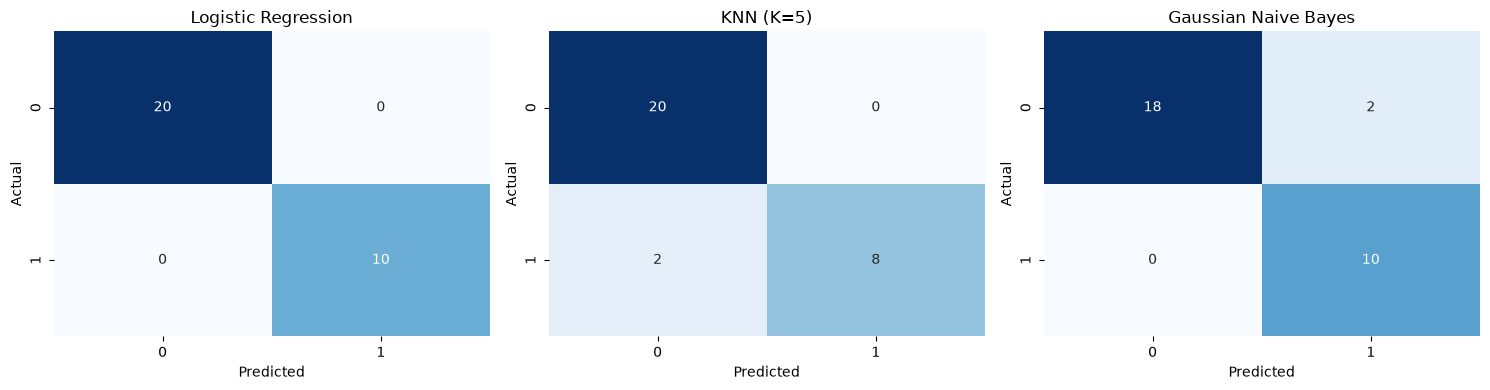

=== Logistic Regression ===
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        20
           1       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30

=== KNN (K=5) ===
              precision    recall  f1-score   support

           0       0.91      1.00      0.95        20
           1       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.95      0.90      0.92        30
weighted avg       0.94      0.93      0.93        30

=== Gaussian Naive Bayes ===
              precision    recall  f1-score   support

           0       1.00      0.90      0.95        20
           1       0.83      1.00      0.91        10

    accuracy                           0.93        30
   macro avg       0.92      0.95      0.93        30

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, pred) in zip(axes, preds.items()):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set(title=name, xlabel="Predicted", ylabel="Actual")
plt.tight_layout()
plt.show()

for name, pred in preds.items():
    print(f"=== {name} ===")
    print(classification_report(y_test, pred, zero_division=0))

### 7. Gaussian Naive Bayes
Train a Gaussian Naive Bayes classifier, which assumes conditional feature independence given the class label. Despite this strong assumption, it often performs competitively on small datasets and provides a probabilistic baseline.

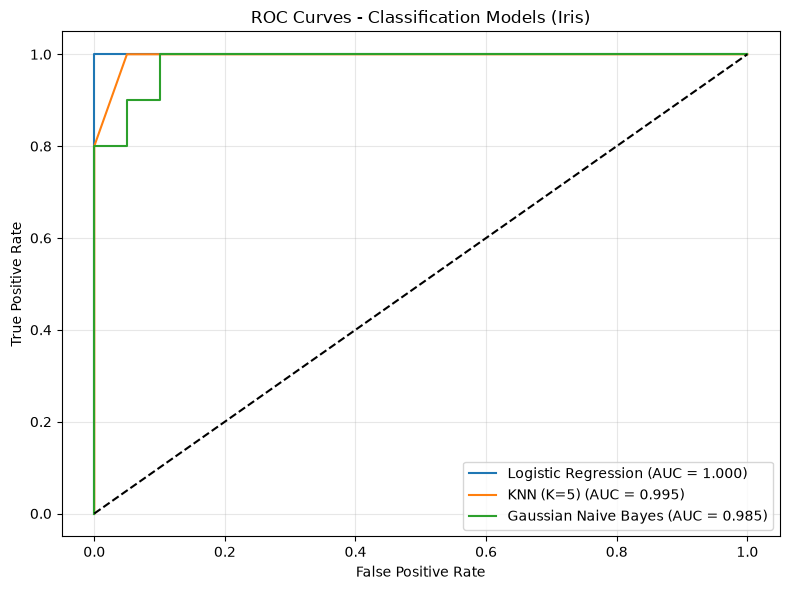

In [8]:
plt.figure(figsize=(8, 6))
for name, prob in probs.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, prob):.3f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Classification Models (Iris)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 8. Model Evaluation — Confusion Matrix & Classification Report
Generate confusion matrices and classification reports (precision, recall, F1-score) for all three models. These metrics provide a richer picture of classifier performance than accuracy alone, particularly under class imbalance.

    K  CV Accuracy   CV F1  CV AUC
0   1       0.9417  0.9171  0.9375
1   3       0.9667  0.9514  0.9656
2   5       0.9583  0.9380  0.9898
3   7       0.9500  0.9247  0.9852
4   9       0.9417  0.9156  0.9883
5  11       0.9417  0.9156  0.9898
6  15       0.9500  0.9264  0.9859


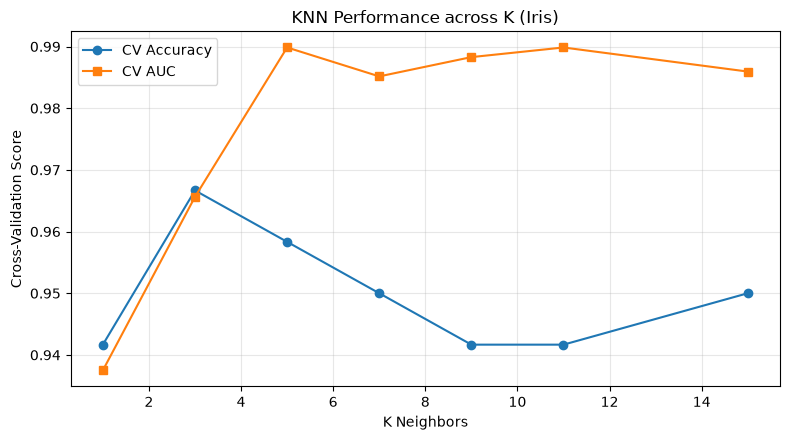

In [9]:
k_rows = []
for k in [1, 3, 5, 7, 9, 11, 15]:
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=k))
    ])
    cv = cross_validate(pipe, X_train, y_train, cv=5, scoring=["accuracy", "f1", "roc_auc"])
    k_rows.append({
        "K": k,
        "CV Accuracy": cv["test_accuracy"].mean(),
        "CV F1": cv["test_f1"].mean(),
        "CV AUC": cv["test_roc_auc"].mean()
    })
knn_results = pd.DataFrame(k_rows)
print(knn_results.round(4))

plt.figure(figsize=(8, 4.5))
plt.plot(knn_results["K"], knn_results["CV Accuracy"], marker="o", label="CV Accuracy")
plt.plot(knn_results["K"], knn_results["CV AUC"], marker="s", label="CV AUC")
plt.xlabel("K Neighbors")
plt.ylabel("Cross-Validation Score")
plt.title("KNN Performance across K (Iris)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 9. ROC Curves & AUC Comparison
Plot Receiver Operating Characteristic curves for all three classifiers on the same axes. The Area Under the Curve (AUC) summarises each model's ability to discriminate between classes across all decision thresholds. AUC = 1.0 is perfect; AUC = 0.5 is no better than random.

                      Accuracy  Precision  Recall      F1    AUC
Model                                                           
Logistic Regression     1.0000     1.0000     1.0  1.0000  1.000
KNN (K=5)               0.9333     1.0000     0.8  0.8889  0.995
Gaussian Naive Bayes    0.9333     0.8333     1.0  0.9091  0.985


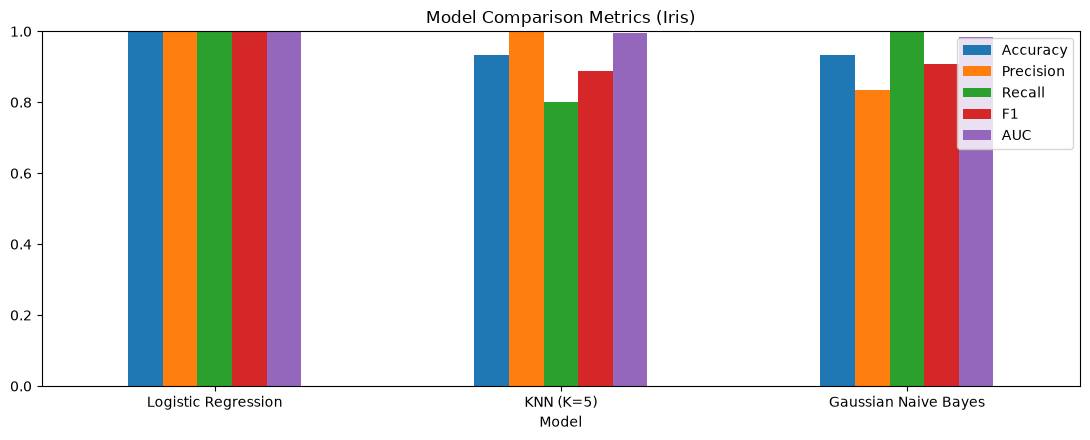

Saved classification results to CSV files.


In [10]:
comparison = pd.DataFrame(results).set_index("Model")
print(comparison.round(4))

comparison.plot(kind="bar", rot=0, figsize=(11, 4.5), ylim=(0, 1))
plt.title("Model Comparison Metrics (Iris)")
plt.tight_layout()
plt.show()

comparison.to_csv("Experiment_8_Classification_Results.csv")
coef_table.to_csv("Experiment_8_Logistic_Coefficients.csv")
knn_results.to_csv("Experiment_8_KNN_Results.csv", index=False)
print("Saved classification results to CSV files.")